In [1]:

import sys; from pathlib import Path; sys.path.insert(0, str(Path.cwd().parents[1]))
import pandas as pd
from common.shortcut import TESTS, MASKS
c = pd.read_csv("../../results/c1_d6_ex3.csv")
c["モデル"] = c["condition"].str.split("_").str[1]
c["訓練"] = c["condition"].str.endswith("token1").map({True: "クラス A に四角", False: "四角なし"})
k = c["metric_name"].str[4:]; c["正解率"] = c["metric_value"] * 100
df = c[k.isin(TESTS)].assign(テスト=k.map(TESTS)); df_mask = c[k.isin(MASKS)].assign(テスト=k.map(MASKS))
clean = df[(df["訓練"] == "四角なし") & (df["テスト"] == TESTS["clean"])].assign(テスト="そのまま")
mask_table = pd.concat([clean, df_mask]).pivot_table(index="モデル", columns="テスト", values="正解率", aggfunc="mean", sort=False)[["そのまま", *MASKS.values()]].round(1)


## (0) 準備

In [1]:
# 授業用フォルダ（AI_TD）のルートを import パスに追加する（ノートブックをどこから開いても動く）
import sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / ".dlcourse_root").exists())
sys.path.insert(0, str(ROOT))
print("作業フォルダ:", ROOT)

作業フォルダ: /Users/konnotakuto/AI_TD


## (確認) 反転テスト

演習2 を思い出して答える．**全問正解すると先へ進める**（ちがうとヒントが出る）．

**Q1**　「A に赤い四角を入れる」（訓練と同じ付け方）のテストで 100% だった．モデルは写真の中身を学んだと言えるか
- ア 言える
- イ 言えない（四角だけで当てていても 100% になる）

**Q2**　「B に赤い四角を入れる」のテストで正解率が大きく下がった．何が分かるか
- ア モデルは赤い四角を手がかりにしていた
- イ テストの写真が難しかった
- ウ 学習のエポックが足りなかった

In [2]:
from common.todo import quiz_check
# ▼ 下の " " の中に，ア・イ・ウのどれかを書いて実行する
Q1 = "イ"
Q2 = "ア"
quiz_check({    # 2 つ目の値は答え合わせ用の暗号（答えは書いていない）
    "Q1": (Q1, "86c731cb", "四角が付いた写真をすべて A と答えるだけで 100% になる"),
    "Q2": (Q2, "eb95be22", "写真は「A に赤い四角を入れる」と全く同じ．変えたのは四角の付け方だけ"),
})

Q1：正解．四角が付いた写真をすべて A と答えるだけで 100% になる
Q2：正解．写真は「A に赤い四角を入れる」と全く同じ．変えたのは四角の付け方だけ
全問正解．実験に進んでよい


## 予測（実行する前に書く）

このセルをダブルクリックして書き込む．クラス A に四角を入れて学習したとき，「B に赤い四角を入れる」の正解率（5 回の平均）は：

- CNN：20％　ResNet18 凍結：20％（赤い四角を拾い，CNN と同じくらい落ちる）
- ResNet18 凍結の「A に赤い四角を入れる」と「B に赤い四角を入れる」に差があると言えるか：差がある

## (1) 20 回を回す

教員機（M4 Max）で約 15 秒．ResNet18 は凍結した本体を 1 回だけ通し，最後の層だけを学習する．

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from common.device import get_device
from common.logger import ResultLogger
from common.mydata import image_dir, diff_ratio, verdict
from common.shortcut import MASKS, TESTS, run
plt.rcParams["font.family"] = ["Hiragino Sans", "sans-serif"]   # Mac の日本語フォント（文字化け防止）

device = get_device()
IMAGE_DIR = image_dir()
SEEDS = [0, 1, 2, 3, 4]
logger = ResultLogger(None, "member1", course="c1", day="d6", exercise="ex3", device=device)
rows, mask_rows = [], []
for kind in ["CNN", "ResNet18"]:
    for token_train in [False, True]:
        train = "クラス A に四角" if token_train else "四角なし"
        for seed in SEEDS:
            r = run(kind, token_train, seed=seed, root=IMAGE_DIR, device=device)
            logger.log_many({f"acc_{t}": a for t, a in {**r["acc"], **r["mask"]}.items()}, condition=f"{IMAGE_DIR.name}_{kind}_token{int(token_train)}", seed=seed)
            for t, a in r["acc"].items():
                rows.append({"モデル": kind, "訓練": train, "テスト": TESTS[t], "シード": seed, "正解率": a * 100})
            for m, a in r["mask"].items():   # 四角なしで学習したときだけ
                mask_rows.append({"モデル": kind, "テスト": MASKS[m], "シード": seed, "正解率": a * 100})
            print(f"{kind} {train} シード {seed}：" + "  ".join(f"{TESTS[t]} {a * 100:.0f}%" for t, a in r["acc"].items()))
df = pd.DataFrame(rows)
df_mask = pd.DataFrame(mask_rows)
print(f"テストは {r['n_test']} 枚．1 枚で {100 / r['n_test']:.1f} ポイント動く")

assets/mydata/ が無いので，ケーブル画像（assets/cable1/）で進めます


CNN 四角なし シード 0：四角なし 87%  A に赤い四角を入れる 90%  B に赤い四角を入れる 83%


CNN 四角なし シード 1：四角なし 70%  A に赤い四角を入れる 73%  B に赤い四角を入れる 70%


CNN 四角なし シード 2：四角なし 87%  A に赤い四角を入れる 80%  B に赤い四角を入れる 87%


CNN 四角なし シード 3：四角なし 90%  A に赤い四角を入れる 90%  B に赤い四角を入れる 90%


CNN 四角なし シード 4：四角なし 90%  A に赤い四角を入れる 90%  B に赤い四角を入れる 90%


... (11 outputs left out)

ResNet18 クラス A に四角 シード 1：四角なし 93%  A に赤い四角を入れる 97%  B に赤い四角を入れる 83%


ResNet18 クラス A に四角 シード 2：四角なし 97%  A に赤い四角を入れる 100%  B に赤い四角を入れる 93%


ResNet18 クラス A に四角 シード 3：四角なし 93%  A に赤い四角を入れる 100%  B に赤い四角を入れる 93%


ResNet18 クラス A に四角 シード 4：四角なし 93%  A に赤い四角を入れる 100%  B に赤い四角を入れる 83%
テストは 30 枚．1 枚で 3.3 ポイント動く


## (2) 平均・標準偏差と，「A に赤い四角を入れる」→「B に赤い四角を入れる」の 差 ÷ 標準偏差

- 差 ÷ 標準偏差 ＝ 2 つの条件の差が，シードを変えたときの揺れの何倍か
- 標準偏差は √((A の標準偏差² ＋ B の標準偏差²) ÷ 2)．例：A に赤い四角を入れる 99.3 ± 1.5，B に赤い四角を入れる 90.0 ± 6.2 → 9.3 ÷ 4.5 ＝ 2.1
- 2 以上：差がある／1 未満：差があるとは言えない／その間：回数を増やして確かめる（5 回だけの粗い目安）

テスト正解率（%）：5 回の平均 ± 標準偏差
テスト                       四角なし A に赤い四角を入れる B に赤い四角を入れる
モデル      訓練                                           
CNN      四角なし       84.7 ± 8.4  84.7 ± 7.7  84.0 ± 8.3
         クラス A に四角  56.7 ± 4.1  99.3 ± 1.5   2.0 ± 1.8
ResNet18 四角なし       98.0 ± 1.8  97.3 ± 2.8  98.0 ± 1.8
         クラス A に四角  95.3 ± 3.0  99.3 ± 1.5  90.0 ± 6.2

CNN      四角なし    ：A に赤い四角を入れる → B に赤い四角を入れる -0.7 ポイント ÷ 標準偏差 8.0 = 0.1 → 差があるとは言えない
CNN      クラス A に四角：A に赤い四角を入れる → B に赤い四角を入れる -97.3 ポイント ÷ 標準偏差 1.7 = 58.4 → 差がある
ResNet18 四角なし    ：A に赤い四角を入れる → B に赤い四角を入れる +0.7 ポイント ÷ 標準偏差 2.4 = 0.3 → 差があるとは言えない
ResNet18 クラス A に四角：A に赤い四角を入れる → B に赤い四角を入れる -9.3 ポイント ÷ 標準偏差 4.5 = 2.1 → 差がある


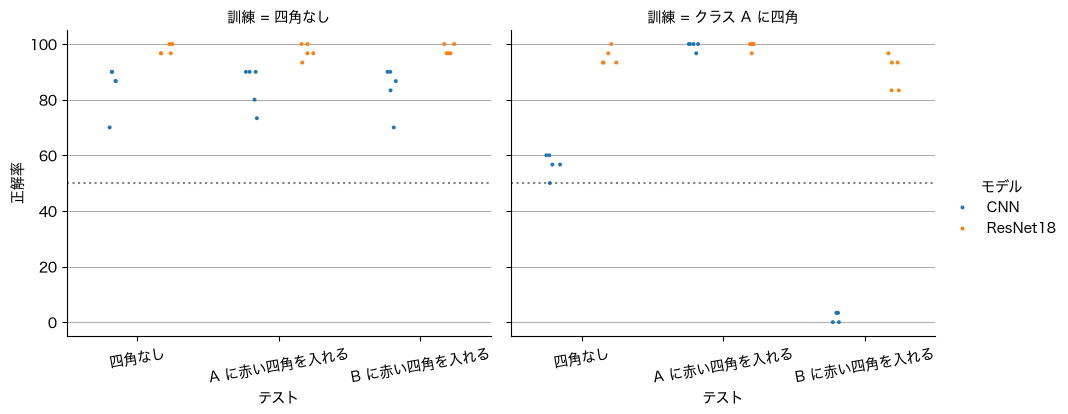

In [4]:
table = df.pivot_table(index=["モデル", "訓練"], columns="テスト", values="正解率", sort=False,
                       aggfunc=lambda v: f"{v.mean():.1f} ± {v.std():.1f}")[list(TESTS.values())]
print("テスト正解率（%）：5 回の平均 ± 標準偏差")
print(table.to_string())
print()
same, flip = TESTS["same"], TESTS["flip"]
for (kind, train), g in df.groupby(["モデル", "訓練"], sort=False):
    a = g[g["テスト"] == same].sort_values("シード")["正解率"].values
    b = g[g["テスト"] == flip].sort_values("シード")["正解率"].values
    diff, sd, ratio = diff_ratio(a, b)
    print(f"{kind:8s} {train:8s}：A に赤い四角を入れる → B に赤い四角を入れる {diff:+.1f} ポイント ÷ 標準偏差 {sd:.1f} = {ratio:.1f} → {verdict(ratio)}")

g = sns.catplot(data=df, x="テスト", y="正解率", hue="モデル", col="訓練", kind="strip", dodge=True, height=4, aspect=1.2, s=8)
g.set_xticklabels(rotation=10)
for ax in g.axes.flat:
    ax.axhline(50, color="gray", linestyle=":")
    ax.grid(True, axis="y")
plt.show()

## (3) 自分の写真で目印を探す：中央を隠す・まわりを隠す

赤い四角は自分で入れた目印．自分の写真にも，気づかない目印（背景・机・明るさなど）が入っているかもしれない．
四角なしで学習したモデル（(1) で学習済み）に，テスト写真の一部を灰色で隠して見せる．

| テスト | 隠す所 | 正解率が高いままなら |
|---|---|---|
| 中央を隠す | 写真の真ん中（縦横の半分）．ふつうは物が写っている所 | 物ではなく，**まわり（背景など）** で当てている |
| まわりを隠す | 真ん中以外 | 物を見て当てている |

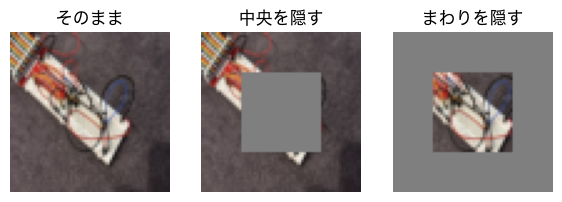

テスト正解率（%）：5 回の平均（四角なしで学習したモデル）
テスト       そのまま  中央を隠す  まわりを隠す
モデル                          
CNN       84.7   82.7    57.3
ResNet18  98.0   69.3    72.0



CNN      そのまま → 中央を隠す：-2.0 ポイント ÷ 標準偏差 7.1 = 0.3 → 差があるとは言えない
CNN      そのまま → まわりを隠す：-27.3 ポイント ÷ 標準偏差 6.7 = 4.1 → 差がある
ResNet18 そのまま → 中央を隠す：-28.7 ポイント ÷ 標準偏差 5.3 = 5.4 → 差がある
ResNet18 そのまま → まわりを隠す：-26.0 ポイント ÷ 標準偏差 3.0 = 8.7 → 差がある


In [5]:
from common.shortcut import hide
from common.mydata import loaders
_, _, test_loader, _ = loaders(seed=0, size=64, root=IMAGE_DIR)
x = test_loader.dataset[0][0]
fig, axes = plt.subplots(1, 3, figsize=(7, 2.6))
for ax, (img, title) in zip(axes, [(x, "そのまま"), (hide(x, "center"), "中央を隠す"), (hide(x, "border"), "まわりを隠す")]):
    ax.imshow(img.permute(1, 2, 0)); ax.set_title(title); ax.axis("off")
plt.show()

clean = df[(df["訓練"] == "四角なし") & (df["テスト"] == TESTS["clean"])].assign(テスト="そのまま")[["モデル", "テスト", "シード", "正解率"]]
both = pd.concat([clean, df_mask])
mask_table = both.pivot_table(index="モデル", columns="テスト", values="正解率", aggfunc="mean", sort=False)[["そのまま", *MASKS.values()]].round(1)
print("テスト正解率（%）：5 回の平均（四角なしで学習したモデル）")
print(mask_table.to_string())
print()
for kind, g in both.groupby("モデル", sort=False):
    a = g[g["テスト"] == "そのまま"].sort_values("シード")["正解率"].values
    for name in MASKS.values():
        b = g[g["テスト"] == name].sort_values("シード")["正解率"].values
        diff, sd, ratio = diff_ratio(a, b)
        print(f"{kind:8s} そのまま → {name}：{diff:+.1f} ポイント ÷ 標準偏差 {sd:.1f} = {ratio:.1f} → {verdict(ratio)}")

## (4) 考察（提出）

下のセルの `""" """` の中に書いて実行する（それぞれ 1〜3 文）．**2〜4 は，(2)・(3) の表の自分の数値（例 90.0）を 1 つ以上入れて根拠にする**．入っていないと止まる．
自分の写真の結果は自分にしか分からない．LLM に書かせず，自分の結果を見て書く．

In [2]:
from common.shortcut import evidence_check
A1 = """予測と比べて，当たったこと・外れたこと：CNN の B に赤い四角を入れるは 20% と予測して 2.0% で，落ちる向きは当たったが予測より低かった．ResNet18 凍結は CNN と同じくらい落ちて 20% と予測したが，実際は 90.0% で外れた．ResNet18 凍結に差があるという予測は当たった（差 ÷ 標準偏差 2.1）"""
A2 = """ResNet18 凍結は，CNN より赤い四角にだまされにくかったか．それはなぜか（学習する所は全部か最後の層だけか，第5回で ImageNet から何を学んだか）：だまされにくかった．CNN は 99.3% から 2.0% へ 97.3 ポイント落ちたが，ResNet18 凍結は 99.3% から 90.0% へ 9.3 ポイントしか落ちなかった．ResNet18 凍結は手前の層を ImageNet で学んだまま固定していて，形や模様の特徴をそのまま使う．学習するのは最後の層だけなので，赤い四角だけに反応する特徴を新しく作れない"""
A3 = """(3) で，自分のモデルは物とまわりのどちらを見て当てていたと言えるか．自分の写真のどんな特徴（背景・机・明るさ・撮った場所など）がそうさせたと考えるか：CNN は中央を隠しても 82.7% でほとんど落ちず，まわりを隠すと 57.3% に落ちたので，ケーブルよりまわりを見て当てていた．ResNet18 は中央を隠すと 69.3%，まわりを隠すと 72.0% でどちらも落ちたので，物とまわりの両方を使っていた．ケーブル画像はクラスごとに床の模様や明るさ，ケーブルの置き方が少しずつ違い，それが手がかりになったと考える"""
A4 = """それを確かめるには，次にどんな写真を撮って，何と何を比べればよいか（反転テストの考え方で）：同じ床・同じ明るさで両方のクラスを撮り，さらにクラス A のケーブルをクラス B でよく使う背景や置き方で撮った写真を用意する．そろえた写真と入れ替えた写真の正解率を比べ，入れ替えた方で大きく落ちれば背景で当てていたと分かる．いまの CNN はまわりを隠すと 84.7% から 57.3% に落ちたので，入れ替えた写真でも同じくらい落ちるかを見る"""
summary_table = df.groupby(["モデル", "訓練", "テスト"])["正解率"].mean().unstack()
evidence_check({"考察2": A2, "考察3": A3, "考察4": A4}, summary_table, mask_table)

考察2 OK：引用した数値 2.0, 90.0, 97.3, 99.3
考察3 OK：引用した数値 57.3, 69.3, 72.0, 82.7
考察4 OK：引用した数値 57.3, 84.7
